# 02 – Fitting FSRS to each learner

Notebook 01 found that FSRS with its **default parameters** predicted these five
learners worse than a constant guess on log loss, and suggested why: FSRS is meant
to be **fitted to each learner**. This notebook tests that.

**What fitting means.** FSRS tracks two numbers per card, *stability* (how many days
until recall drops to 90%) and *difficulty*. About 20 parameters decide how those
numbers move after each answer, e.g. `w[2]` is the starting stability after a first
"Good". Fitting runs gradient descent (in PyTorch) over a learner's past reviews and
adjusts the parameters until FSRS's predictions match that learner's answers best.

**Rules:** each learner's parameters are fitted **only on reviews before their
test period** (no peeking at the future), and both models are scored on the same
test reviews as in notebook 01. Fitting is slow on a CPU, so it uses a fixed random
sample of 3,000 cards per learner.

This is exactly what will happen in the app: `forglemmigej_api.training.fit_fsrs`
fits the learner's own reviews and registers the result as a **challenger**, which
then predicts every review in shadow mode next to the champion.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forglemmigej_api.features import HISTORY_FEATURES
from forglemmigej_api.scheduling import FsrsModel, predict_from_history
from forglemmigej_api.training.evaluate import calibration_table, chronological_split, score
from forglemmigej_api.training.fit_fsrs import fit_parameters
from forglemmigej_api.training.models import fit_lightgbm, predict
from forglemmigej_api.training.public import read_user_histories

pd.set_option("display.precision", 4)
RAW = Path("../data/raw/fsrs-dataset")
data = pd.read_parquet("../data/processed/public_examples.parquet")
data["recalled"] = data["recalled"].astype(int)
train, test = chronological_split(data, test_fraction=0.2, group="user")
DEFAULT = FsrsModel("fsrs6-default", (
    0.212, 1.2931, 2.3065, 8.2956, 6.4133, 0.8334, 3.0194, 0.001, 1.8722, 0.1666, 0.796,
    1.4835, 0.0614, 0.2629, 1.6483, 0.6014, 1.8729, 0.5425, 0.0912, 0.0658, 0.1542,
))
print(f"train {len(train):,}   test {len(test):,}")

train 1,073,689   test 268,423


## Fit one learner at a time

For each learner: take their reviews up to the end of their training period, fit
FSRS on a sample of cards, then predict each of their test reviews by replaying that
card's history with the fitted parameters. The replay is the same code the app uses
for challengers in shadow mode (`predict_from_history`).

In [2]:
rng = np.random.default_rng(0)
fitted_params, fitted_pred = {}, pd.Series(np.nan, index=test.index)

for user, user_test in test.groupby("user"):
    histories = read_user_histories(RAW / f"revlog_history-{user}.tsv")
    cutoff = train.loc[train["user"] == user, "reviewed_at"].max()
    keys = list(histories)
    sample = rng.choice(len(keys), size=min(3000, len(keys)), replace=False)
    fit_data = {
        int(i): [r for r in histories[keys[i]] if r.reviewed_at <= cutoff]
        for i in sample
    }
    fit_data = {k: v for k, v in fit_data.items() if v}
    started = time.perf_counter()
    params = fit_parameters(fit_data)
    fitted_params[user] = params
    model = FsrsModel(f"fitted-{user}", tuple(params))
    fitted_pred[user_test.index] = [
        predict_from_history(model, histories[card], at)
        for card, at in zip(user_test["card_id"], user_test["reviewed_at"])
    ]
    n = sum(len(v) for v in fit_data.values())
    print(f"{user}: fitted on {n:,} reviews in {time.perf_counter() - started:.0f}s")

05ff595: fitted on 17,111 reviews in 262s


23e35f5: fitted on 23,505 reviews in 260s


27e8453: fitted on 11,095 reviews in 109s


4181a16: fitted on 29,446 reviews in 304s


48a935a: fitted on 22,401 reviews in 221s


## Default vs fitted, with LightGBM from notebook 01 for reference

In [3]:
features = [f for f in HISTORY_FEATURES if f != "log_last_response_s"]
lightgbm = fit_lightgbm(train, features)
predictions = {
    "FSRS default (champion)": test["fsrs_recall"].to_numpy(),
    "FSRS fitted per learner (challenger)": fitted_pred.to_numpy(),
    "LightGBM (notebook 01)": predict(lightgbm, test, features),
    "constant": np.full(len(test), train["recalled"].mean()),
}
results = pd.DataFrame({name: score(test["recalled"], p).as_dict() for name, p in predictions.items()}).T
results.drop(columns="n").sort_values("log_loss")

,log_loss,brier,auc,rmse_bins
LightGBM (notebook 01),0.3339,0.0968,0.6936,0.0270
constant,0.3588,0.1020,0.5000,0.0208
FSRS fitted per learner (challenger),0.3885,0.0957,0.7051,0.0210
FSRS default (champion),0.4054,0.0994,0.6453,0.0359


In [4]:
rows = []
for user, part in test.groupby("user"):
    idx = test.index.get_indexer(part.index)
    rows.append({
        "user": user,
        "n": len(part),
        "default": score(part["recalled"], predictions["FSRS default (champion)"][idx]).log_loss,
        "fitted": score(part["recalled"], predictions["FSRS fitted per learner (challenger)"][idx]).log_loss,
    })
per_user = pd.DataFrame(rows).set_index("user")
per_user["improvement"] = 1 - per_user["fitted"] / per_user["default"]
per_user["fitted wins"] = per_user["fitted"] < per_user["default"]
per_user

,n,default,fitted,improvement,fitted wins
user,,,,,
05ff595,89132,0.1940,0.1658,0.1454,True
23e35f5,42339,0.6548,0.6452,0.0146,True
27e8453,17179,0.4663,0.4459,0.0436,True
4181a16,76174,0.4204,0.4040,0.0390,True
48a935a,43599,0.5450,0.5447,0.0005,True


### Calibration

The scheduler acts on the probability itself (a card is due when it falls below
90%), so calibration matters more than ranking here.

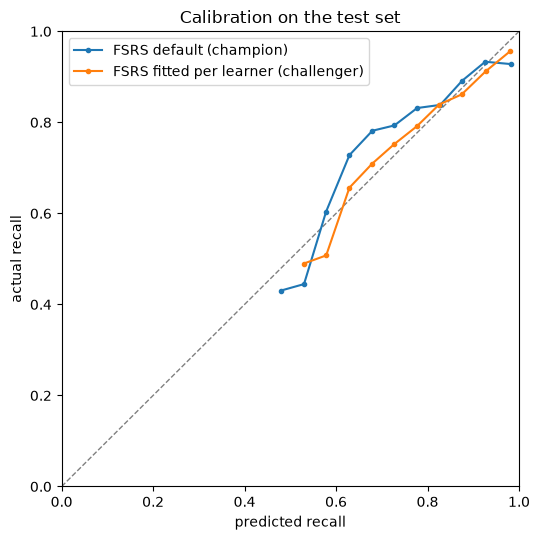

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
for name in ["FSRS default (champion)", "FSRS fitted per learner (challenger)"]:
    table = calibration_table(test["recalled"], predictions[name])
    table = table[table["n"] >= 200]
    ax.plot(table["predicted"], table["actual"], marker="o", markersize=3, label=name)
ax.set(xlabel="predicted recall", ylabel="actual recall", title="Calibration on the test set", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.tight_layout()

### What changed in the parameters?

The first four are the starting stabilities (in days) after a first Again, Hard,
Good or Easy. Learners whose memories last longer than average get larger values.

In [6]:
params = pd.DataFrame(fitted_params, index=[f"w{i}" for i in range(len(DEFAULT.parameters))])
params.insert(0, "default", DEFAULT.parameters)
params.round(3)

,default,05ff595,23e35f5,27e8453,4181a16,48a935a
w0,0.212,1.399,0.993,0.795,1.531,0.122
w1,1.293,2.825,0.148,1.718,1.952,1.293
w2,2.306,4.020,1.309,3.319,4.921,1.745
w3,8.296,10.506,10.843,8.761,10.276,8.296
w4,6.413,5.601,6.458,5.827,7.710,6.737
w5,0.833,0.633,0.974,0.856,1.020,0.316
w6,3.019,4.000,3.553,3.319,3.956,3.076
w7,0.001,0.001,0.001,0.001,0.001,0.016
w8,1.872,2.634,1.876,2.535,2.180,1.637
w9,0.167,0.072,0.179,0.419,0.569,0.000


## Conclusions

| model | log loss | Brier | AUC | calibration error |
|---|---|---|---|---|
| FSRS default (champion) | 0.405 | 0.099 | 0.645 | 0.036 |
| **FSRS fitted per learner (challenger)** | 0.389 | **0.096** | **0.705** | 0.021 |
| LightGBM (notebook 01) | **0.334** | 0.097 | 0.694 | 0.027 |
| constant guess | 0.359 | 0.102 | 0.500 | 0.021 |

1. **Fitting helps every learner.** The fitted FSRS beats the default on log loss for all five (from 0.05% to 15% better), and it is better calibrated: its curve hugs the diagonal where the default was underconfident in the middle range.
2. **The fitted FSRS ranks cards best of all** (highest AUC) **and has the lowest Brier score**, better than LightGBM. With only ~20 parameters and a sample of 3,000 cards per learner, that is a strong result.
3. **But on log loss it still loses to LightGBM and even to the constant guess.** Log loss punishes confident mistakes very hard. FSRS often predicts 98–99% recall, and a card forgotten at 99% costs a lot (the top bin shows ~95% actual recall). LightGBM hedges more, which log loss rewards.
4. **The metrics disagree, so the choice of metric is a decision, not a detail.** For scheduling, what matters is whether the probability is right around the 90% threshold, which favours calibration and Brier. Log loss stays the primary gate metric (it is the standard for probabilistic predictions), but the gate also has to check calibration. A model that wins log loss by hedging, but schedules worse, should not win automatically.
5. **The parameters really differ between learners.** For example, `w2`, the starting stability after a first "Good", ranges from 1.3 to 4.9 days against a default of 2.3. One size does not fit all, which is the whole point of personalisation.

**For forglemmigej:** once the learner has about a thousand reviews, `fit_fsrs` registers a fitted challenger. It then predicts every review in shadow mode, and the promotion gate compares it with the champion on exactly the same reviews, on log loss and calibration. Same-day learning-step reviews say little (every model predicts ~100% minutes after learning), so the gate should look at reviews at least a day after the previous one.
